In [49]:
print("this is 2nd basic project ")


this is 2nd basic project 


In [50]:
import pandas  as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 
import sklearn 


In [51]:
df= pd.read_csv("heart.csv")

In [52]:
df  # here we need to predict the possibility of the heart attacks 


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1


In [53]:
df.shape

(918, 12)

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='str')


<Axes: xlabel='HeartDisease'>

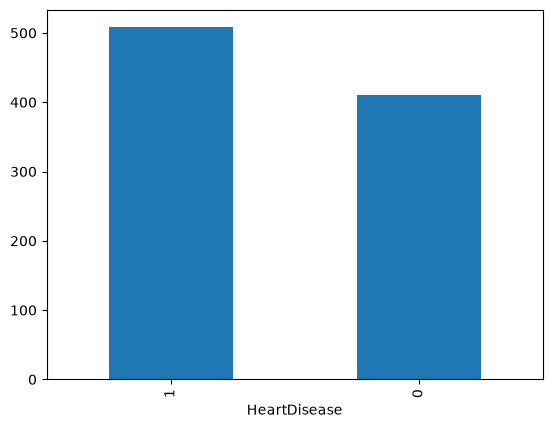

In [54]:
print(df.columns)
df.describe()
df['HeartDisease'].value_counts().plot(kind="bar") # distribution

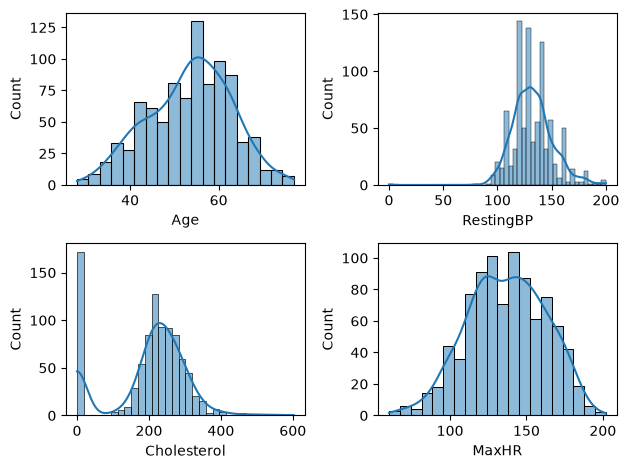

In [55]:
def plotting(var , num):
    plt.subplot(2,2,num)
    sns.histplot(df[var] , kde=True)
plotting('Age', 1) # normal distribution
plotting('RestingBP', 2)
plotting('Cholesterol', 3)
plotting('MaxHR', 4) # normal distribution 
plt.tight_layout()



In [56]:
df_clean =df.copy()

In [57]:
df_clean=pd.get_dummies(df_clean,columns=['RestingECG'], drop_first=True)

In [58]:
df_clean=pd.get_dummies(df_clean,columns=['ChestPainType'], drop_first=True)

In [59]:
df_clean=pd.get_dummies(df_clean,columns=['Sex','ExerciseAngina','ST_Slope'], drop_first=True)

In [60]:
df_clean

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,RestingECG_Normal,RestingECG_ST,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,Sex_M,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0.0,0,True,False,True,False,False,True,False,False,True
1,49,160,180,0,156,1.0,1,True,False,False,True,False,False,False,True,False
2,37,130,283,0,98,0.0,0,False,True,True,False,False,True,False,False,True
3,48,138,214,0,108,1.5,1,True,False,False,False,False,False,True,True,False
4,54,150,195,0,122,0.0,0,True,False,False,True,False,True,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,110,264,0,132,1.2,1,True,False,False,False,True,True,False,True,False
914,68,144,193,1,141,3.4,1,True,False,False,False,False,True,False,True,False
915,57,130,131,0,115,1.2,1,True,False,False,False,False,True,True,True,False
916,57,130,236,0,174,0.0,1,False,False,True,False,False,False,False,True,False


In [61]:
df_clean =df_clean.astype(int)

In [62]:
df_clean

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,RestingECG_Normal,RestingECG_ST,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,Sex_M,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0,0,1,0,1,0,0,1,0,0,1
1,49,160,180,0,156,1,1,1,0,0,1,0,0,0,1,0
2,37,130,283,0,98,0,0,0,1,1,0,0,1,0,0,1
3,48,138,214,0,108,1,1,1,0,0,0,0,0,1,1,0
4,54,150,195,0,122,0,0,1,0,0,1,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,110,264,0,132,1,1,1,0,0,0,1,1,0,1,0
914,68,144,193,1,141,3,1,1,0,0,0,0,1,0,1,0
915,57,130,131,0,115,1,1,1,0,0,0,0,1,1,1,0
916,57,130,236,0,174,0,1,0,0,1,0,0,0,0,1,0


In [63]:
df_clean.info()
df_clean.size

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Age                918 non-null    int64
 1   RestingBP          918 non-null    int64
 2   Cholesterol        918 non-null    int64
 3   FastingBS          918 non-null    int64
 4   MaxHR              918 non-null    int64
 5   Oldpeak            918 non-null    int64
 6   HeartDisease       918 non-null    int64
 7   RestingECG_Normal  918 non-null    int64
 8   RestingECG_ST      918 non-null    int64
 9   ChestPainType_ATA  918 non-null    int64
 10  ChestPainType_NAP  918 non-null    int64
 11  ChestPainType_TA   918 non-null    int64
 12  Sex_M              918 non-null    int64
 13  ExerciseAngina_Y   918 non-null    int64
 14  ST_Slope_Flat      918 non-null    int64
 15  ST_Slope_Up        918 non-null    int64
dtypes: int64(16)
memory usage: 114.9 KB


14688

In [64]:
df_clean=df_clean.drop_duplicates()

In [65]:
df_clean.size

14688

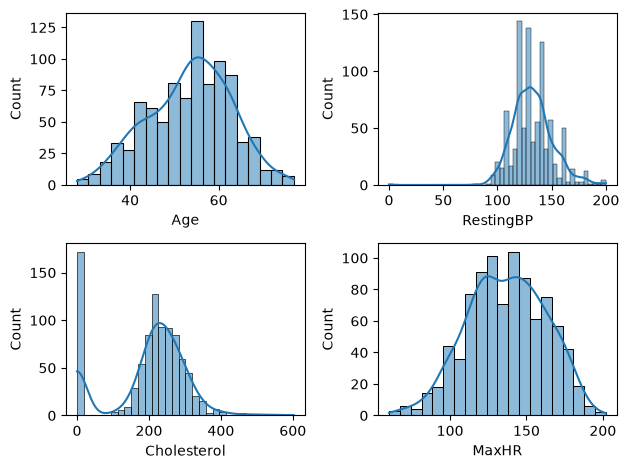

In [66]:
def plotting(var , num):
    plt.subplot(2,2,num)
    sns.histplot(df_clean[var] , kde=True)
plotting('Age', 1) # normal distribution
plotting('RestingBP', 2)
plotting('Cholesterol', 3)
plotting('MaxHR', 4) # normal distribution 
plt.tight_layout()



In [67]:
df_clean['Cholesterol']

0      289
1      180
2      283
3      214
4      195
      ... 
913    264
914    193
915    131
916    236
917    175
Name: Cholesterol, Length: 918, dtype: int64

In [68]:
ch_mean= df_clean.loc[df_clean['Cholesterol'] != 0, 'Cholesterol'].mean()

In [69]:
ch_mean

np.float64(244.6353887399464)

In [70]:
df_clean['Cholesterol']=df_clean['Cholesterol'].replace(0,ch_mean)

In [71]:
df_clean

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,RestingECG_Normal,RestingECG_ST,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,Sex_M,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140,289.0,0,172,0,0,1,0,1,0,0,1,0,0,1
1,49,160,180.0,0,156,1,1,1,0,0,1,0,0,0,1,0
2,37,130,283.0,0,98,0,0,0,1,1,0,0,1,0,0,1
3,48,138,214.0,0,108,1,1,1,0,0,0,0,0,1,1,0
4,54,150,195.0,0,122,0,0,1,0,0,1,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,110,264.0,0,132,1,1,1,0,0,0,1,1,0,1,0
914,68,144,193.0,1,141,3,1,1,0,0,0,0,1,0,1,0
915,57,130,131.0,0,115,1,1,1,0,0,0,0,1,1,1,0
916,57,130,236.0,0,174,0,1,0,0,1,0,0,0,0,1,0


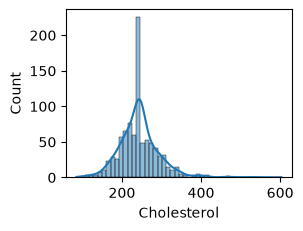

In [72]:
plotting('Cholesterol',3)

In [73]:
rb_mean= df_clean.loc[df_clean["RestingBP"]!=0, 'RestingBP'].mean()

In [74]:
rb_mean

np.float64(132.54089422028352)

In [75]:
df_clean['RestingBP']=df_clean['RestingBP'].replace(0,rb_mean)


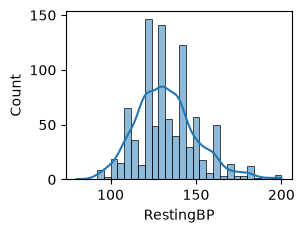

In [76]:
plotting("RestingBP",2)

In [77]:
df_clean.columns

Index(['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak',
       'HeartDisease', 'RestingECG_Normal', 'RestingECG_ST',
       'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'Sex_M',
       'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up'],
      dtype='str')

In [78]:
df.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='str')

<Axes: xlabel='Sex'>

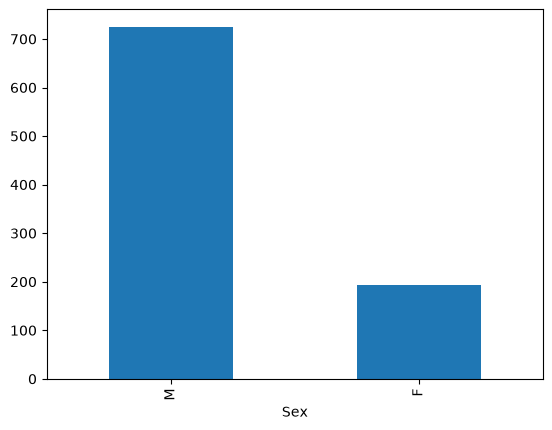

In [79]:
df['Sex'].value_counts().plot(kind="bar")

<Axes: xlabel='Sex', ylabel='count'>

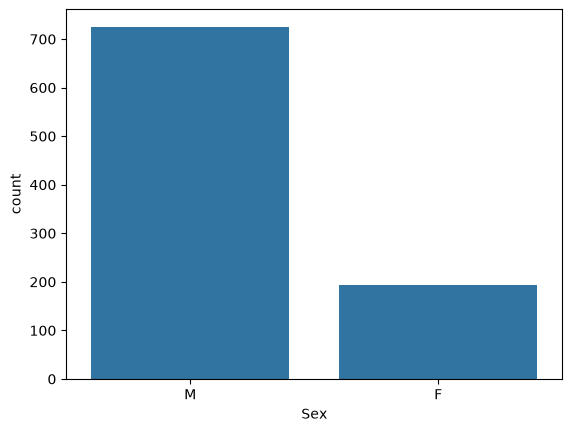

In [80]:
sns.countplot(x=df["Sex"])


<Axes: >

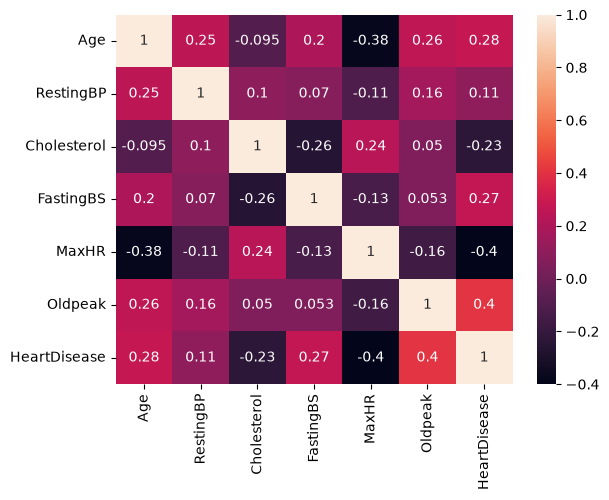

In [81]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

In [82]:
from sklearn.preprocessing import StandardScaler
numeric_cols=[	"Age",	"FastingBS","MaxHR",	"Oldpeak",	"HeartDisease","RestingECG_Normal"	,"RestingECG_ST",	"ChestPainType_ATA",	"ChestPainType_NAP",	"ChestPainType_TA",	"Sex_M",	"ExerciseAngina_Y",	"ST_Slope_Flat",	"ST_Slope_Up"]
scaler=StandardScaler()
df_clean[numeric_cols]= scaler.fit_transform(df_clean[numeric_cols])

In [83]:
df_clean.select_dtypes(include="int")

""
0
1
2
3
4
...
913
914
915
916


In [84]:
df_clean

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,RestingECG_Normal,RestingECG_ST,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,Sex_M,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,-1.433140,140.0,289.0,-0.551341,1.382928,-0.727592,-1.113115,0.814275,-0.490449,2.075177,-0.532838,-0.229679,0.515952,-0.823556,-1.002181,1.150674
1,-0.478484,160.0,180.0,-0.551341,0.754157,0.282891,0.898380,0.814275,-0.490449,-0.481887,1.876744,-0.229679,-1.938163,-0.823556,0.997824,-0.869056
2,-1.751359,130.0,283.0,-0.551341,-1.525138,-0.727592,-1.113115,-1.228087,2.038947,2.075177,-0.532838,-0.229679,0.515952,-0.823556,-1.002181,1.150674
3,-0.584556,138.0,214.0,-0.551341,-1.132156,0.282891,0.898380,0.814275,-0.490449,-0.481887,-0.532838,-0.229679,-1.938163,1.214246,0.997824,-0.869056
4,0.051881,150.0,195.0,-0.551341,-0.581981,-0.727592,-1.113115,0.814275,-0.490449,-0.481887,1.876744,-0.229679,0.515952,-0.823556,-1.002181,1.150674
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,-0.902775,110.0,264.0,-0.551341,-0.188999,0.282891,0.898380,0.814275,-0.490449,-0.481887,-0.532838,4.353909,0.515952,-0.823556,0.997824,-0.869056
914,1.536902,144.0,193.0,1.813758,0.164684,2.303858,0.898380,0.814275,-0.490449,-0.481887,-0.532838,-0.229679,0.515952,-0.823556,0.997824,-0.869056
915,0.370100,130.0,131.0,-0.551341,-0.857069,0.282891,0.898380,0.814275,-0.490449,-0.481887,-0.532838,-0.229679,0.515952,1.214246,0.997824,-0.869056
916,0.370100,130.0,236.0,-0.551341,1.461525,-0.727592,0.898380,-1.228087,-0.490449,2.075177,-0.532838,-0.229679,-1.938163,-0.823556,0.997824,-0.869056


In [85]:
df_clean.columns

Index(['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak',
       'HeartDisease', 'RestingECG_Normal', 'RestingECG_ST',
       'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'Sex_M',
       'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up'],
      dtype='str')

In [86]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report , f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

In [87]:
x= df_clean.drop(['HeartDisease'],axis=1)

In [88]:
y=df['HeartDisease']

In [89]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=42)

In [90]:
scaler = StandardScaler()
x_train_scaled=scaler.fit_transform(X_train)
x_test_scaled=scaler.fit_transform(X_test)

In [91]:
models={
    "Logistic regression":LogisticRegression(),
    "Naive_bayes":GaussianNB(),
    "DecisionTree":DecisionTreeClassifier(),
    "kNN":KNeighborsClassifier(),
    "svm":SVC()
}

In [92]:
result=[]
for name ,model in models.items():
    model.fit(x_train_scaled,y_train)
    y_pred=model.predict(x_test_scaled)
    acc=accuracy_score(y_test,y_pred)
    f1= f1_score(y_test,y_pred)
    result.append({
        "Model":name,
        "f1_score":round(f1,3),
        "accuracy":round(acc,3)
        
        
    })

    

In [93]:
result

[{'Model': 'Logistic regression', 'f1_score': 0.885, 'accuracy': 0.87},
 {'Model': 'Naive_bayes', 'f1_score': 0.875, 'accuracy': 0.861},
 {'Model': 'DecisionTree', 'f1_score': 0.786, 'accuracy': 0.765},
 {'Model': 'kNN', 'f1_score': 0.877, 'accuracy': 0.861},
 {'Model': 'svm', 'f1_score': 0.866, 'accuracy': 0.848}]

In [94]:
import joblib
joblib.dump(models["kNN"],"KNN.pkl")
joblib.dump(scaler,"scaler.pkl")
joblib.dump(x.columns.to_list(),"columns.pkl")


['columns.pkl']